In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats


# Plotting
set_matplotlib_formats("retina")

plt.style.use(
    "https://raw.githubusercontent.com/"
    "ksingh1121/python-plot-style/main/physics.mplstyle"
)

In [2]:
from slmsuite.hardware.slms.meadowlark import Meadowlark
from slmsuite.hardware.cameras.alliedvision import AlliedVision
from slmsuite.hardware.cameraslms import FourierSLM

# Paths

SDK_PATH = Path(
    r"C:\Program Files\Meadowlark Optics\Blink 1920 HDMI\SDK"
)

LUT_PATH = Path(
    r"C:\Users\admin\Desktop\Projects\SLM\SLM tests\Scripts\Experiment scripts"
    r"\LUT_locked_759nm_20260811_201109\759nm_KS_global_20260811.lut"
)

WAVEFRONT_PHASE_PATH = Path(
    r"C:\Users\admin\Desktop\Projects\SLM\SLM tests\Scripts\4f alignment scripts"
    r"\YDFC_wavefront_phase_processed_R2p80_50ms_dark.npy"
)



# Initialize hardware ONCE in this notebook


slm = Meadowlark(
    slm_number=1,
    sdk_path=str(SDK_PATH),
    lut_path=str(LUT_PATH),
    wav_um=0.7593,
    verbose=True,
)

# cam = AlliedVision(
#     serial="015C2",
#     verbose=True,
# )

# fs = FourierSLM(cam, slm)

# cal_file = r"c:\Users\admin\Desktop\Projects\SLM\SLM tests\Scripts\4f alignment scripts\YDFC_fourier_pre_wavefront_00000.h5"

# loaded = fs.load_calibration(
#     "fourier",
#     file_path=cal_file
# )

# print("Loaded:", loaded)
# print("Current calibrations:", fs.calibrations.keys())

# print("Current calibrations:")
# print(fs.calibrations.keys())


# ------------------------------------------------------------
# Load the measured correction from disk
#
# This only creates a NumPy array called wavefront_phase.
# It does NOT activate the correction.
# ------------------------------------------------------------

wavefront_phase = np.load(WAVEFRONT_PHASE_PATH)

# Activate measured wavefront correction in slmsuite
slm.source["phase"] = wavefront_phase.copy()

print("SLM source keys:", slm.source.keys())
print("Wavefront correction enabled:", slm.phase_correct)
print("Correction shape:", slm.source["phase"].shape)

# ------------------------------------------------------------
# Inspect our starting state
# ------------------------------------------------------------

print("SLM shape:", slm.shape)
# print("Camera shape:", cam.shape)

print("\nLoaded correction:")
print(" shape :", wavefront_phase.shape)
print(" finite:", np.all(np.isfinite(wavefront_phase)))
print(" min   :", wavefront_phase.min())
print(" max   :", wavefront_phase.max())

print("\nCurrent slm.source keys:")
print(slm.source.keys())

print("\nGlobal default slm.phase_correct:")
print(slm.phase_correct)

c:\Users\admin\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\slmsuite\holography\algorithms\_header.py:30: UserWarning: cupy is not installed; using numpy. Install cupy for faster GPU-based holography.
  warnings.warn(


Validating DPI awareness...success
Constructing Blink SDK...success
Loading LUT file...SLM source keys: dict_keys(['phase'])
Wavefront correction enabled: True
Correction shape: (1200, 1920)
SLM shape: (1200, 1920)

Loaded correction:
 shape : (1200, 1920)
 finite: True
 min   : 0.0
 max   : 6.2831762207757835

Current slm.source keys:
dict_keys(['phase'])

Global default slm.phase_correct:
True


In [ ]:
# ============================================================
# L1 LONGITUDINAL ALIGNMENT TEST
#
# New relay:
#
#       L1 = 300 mm
#       L2 = 1000 mm
#       M  = f2/f1 = 1000/300 = 3.333...
#
# Generate THREE SEPARATE carrier patterns:
#
#       12 px     16 px     24 px
#
# The 16-pixel carrier defines the nominal optical/cage axis.
#
# 12 px and 24 px are chosen because they are exactly
# symmetric around 16 px in SPATIAL FREQUENCY:
#
#       1/12 - 1/16 = 1/16 - 1/24 = 1/48
#
# Therefore their diffraction-angle offsets relative to the
# 16-px beam are equal and opposite (paraxial approximation).
#
# IMPORTANT:
# This SLM phase pattern does NOT depend on L1 or L2 focal
# length. Changing from 250/750 mm to 300/1000 mm only changes
# how these angular differences propagate through the relay.
#
# All three carriers use exactly the SAME small circular patch.
# Everything outside the patch is sent to a separate dump order.
# ============================================================

import numpy as np

ny, nx = slm.shape

# SLM pixel pitch
pixel_mm = 0.008       # 8 um


# ============================================================
# PARAMETERS
# ============================================================

# Centre of the small alignment patch on the SLM
X0_MM = -0
Y0_MM =  0.15

# Diameter of test patch
# PATCH_DIAMETER_MM = 9.6-0.15
PATCH_DIAMETER_MM = 1.5

# Carrier periods used for longitudinal alignment test
CARRIER_PERIODS_PX = [12, 16, 24]

# Dump grating outside the alignment patch
DUMP_PERIOD_PX = 4
DUMP_DIRECTION = "y"


# ============================================================
# SLM COORDINATES
# ============================================================

cx = (nx - 1) / 2
cy = (ny - 1) / 2

yy, xx = np.indices((ny, nx))

x_px = xx - cx
y_px = yy - cy

x_mm = x_px * pixel_mm
y_mm = y_px * pixel_mm


# Coordinates relative to alignment-patch centre
X = x_mm - X0_MM
Y = y_mm - Y0_MM

R = np.sqrt(X**2 + Y**2)

# Circular test patch
patch = R <= PATCH_DIAMETER_MM / 2


# ============================================================
# OUTER DUMP GRATING
# ============================================================

if DUMP_DIRECTION == "x":
    dump_coordinate = x_px

elif DUMP_DIRECTION == "y":
    dump_coordinate = y_px

else:
    raise ValueError("DUMP_DIRECTION must be 'x' or 'y'")


phase_dump = 2 * np.pi * dump_coordinate / DUMP_PERIOD_PX
phase_dump = np.mod(phase_dump, 2*np.pi)


# ============================================================
# CREATE 12-, 16-, AND 24-PIXEL CARRIER HOLOGRAMS
# ============================================================

patterns = {}

for period_px in CARRIER_PERIODS_PX:

    # --------------------------------------------------------
    # Linear phase ramp
    #
    # phi(x) = 2*pi*x / Lambda
    #
    # where Lambda = period_px * SLM pixel pitch.
    #
    # This produces diffraction approximately at
    #
    # theta = lambda / Lambda
    #
    # for small angles.
    # --------------------------------------------------------

    phase_carrier = 2 * np.pi * x_px / period_px
    phase_carrier = np.mod(phase_carrier, 2*np.pi)

    # Start with the dump pattern everywhere
    phase_test = phase_dump.copy()

    # Replace only the small circular patch with the
    # desired test carrier
    phase_test[patch] = phase_carrier[patch]

    phase_test = np.mod(phase_test, 2*np.pi)

    patterns[period_px] = phase_test


# Convenient individual variables
phase_12 = patterns[12]
phase_16 = patterns[16]
phase_24 = patterns[24]


# ============================================================
# INFORMATION
# ============================================================

print("L1 longitudinal-alignment patterns created")
print()
print("New relay:")
print("    L1 = 300 mm")
print("    L2 = 1000 mm")
print("    M  =", 1000/300)
print()
print("Patch diameter :", PATCH_DIAMETER_MM, "mm")
print("Patch centre   :", X0_MM, Y0_MM, "mm")
print("Carriers       :", CARRIER_PERIODS_PX, "pixels")
print()
print("16 px = nominal cage / optical axis")
print("12 px and 24 px are symmetric around 16 px in spatial frequency.")

L1 longitudinal-alignment patterns created

New relay:
    L1 = 300 mm
    L2 = 1000 mm
    M  = 3.3333333333333335

Patch diameter : 1.5 mm
Patch centre   : -1.0 0.15 mm
Carriers       : [12, 16, 24] pixels

16 px = nominal cage / optical axis
12 px and 24 px are symmetric around 16 px in spatial frequency.


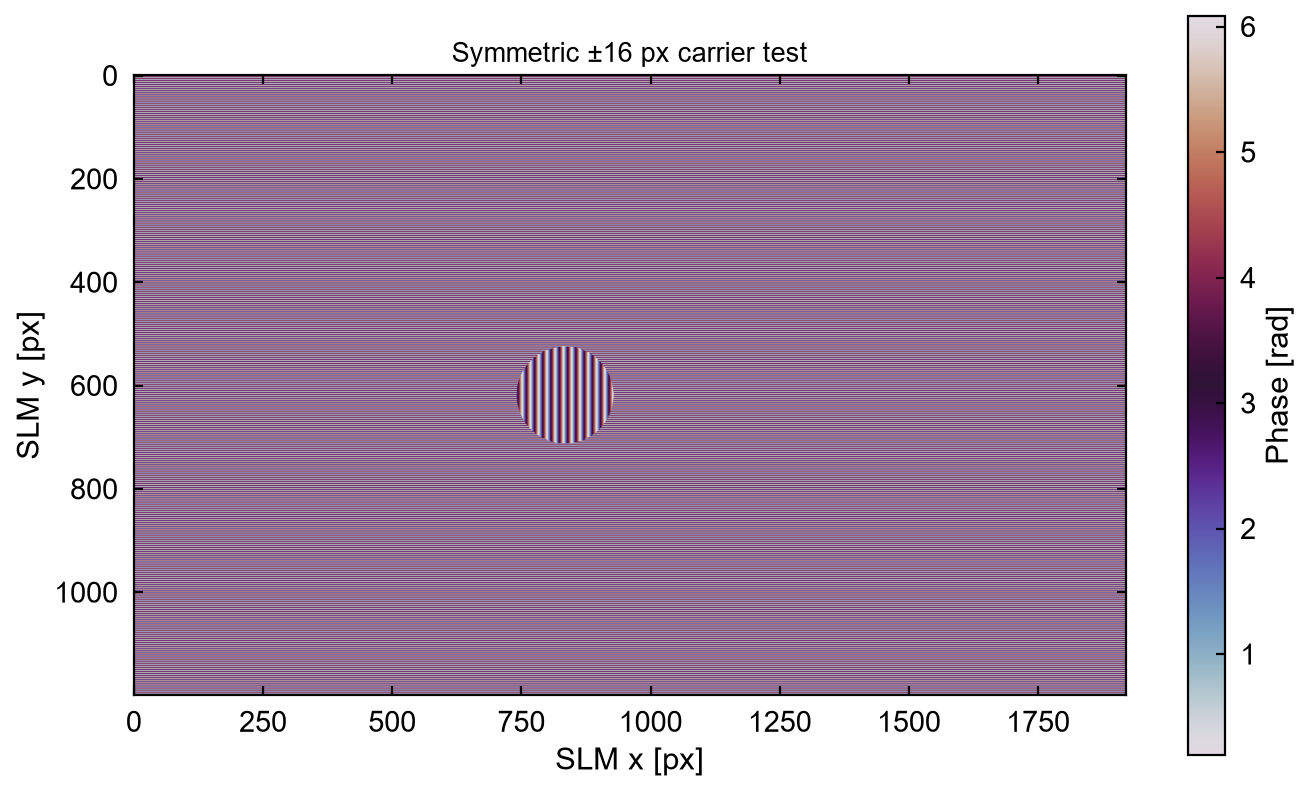

In [10]:
# import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
plt.imshow(
    phase_16,
    cmap="twilight",
    origin="upper"
)
plt.colorbar(label="Phase [rad]")
plt.title("Symmetric ±16 px carrier test")
plt.xlabel("SLM x [px]")
plt.ylabel("SLM y [px]")
plt.show()

In [11]:
# 12-pixel carrier
# slm.set_phase(
#     phase_12,
#     phase_correct=True,   # uses slm.source["phase"] if present
#     settle=True,
# )




# # 16-pixel carrier

slm.set_phase(
    phase_16,
    phase_correct=True,   # uses slm.source["phase"] if present
    settle=True,
)



# 24-pixel carrier
# slm.set_phase(
#     phase_24,
#     phase_correct=True,   # uses slm.source["phase"] if present
#     settle=True,
# )

array([[209, 209, 209, ..., 238, 238, 238],
       [145, 145, 145, ..., 174, 174, 174],
       [ 81,  81,  81, ..., 110, 110, 110],
       ...,
       [  2,   2,   2, ...,  31,  31,  31],
       [194, 194, 194, ..., 223, 223, 223],
       [130, 130, 130, ..., 159, 159, 159]],
      shape=(1200, 1920), dtype=uint8)

In [12]:
# import time

# # 16-pixel carrier
# phase_correct = True

# try:
#     while True:
#         print(f"Wavefront correction: {phase_correct}")

#         slm.set_phase(
#             phase_16,
#             phase_correct=phase_correct,
#             settle=True,
#         )

#         time.sleep(1)

#         # Toggle True <-> False
#         phase_correct = not phase_correct

# except KeyboardInterrupt:
#     print("Stopped toggling.")

### Analysis


In [11]:
# ============================================================
# L1 LONGITUDINAL ALIGNMENT TEST
#
# SIMULTANEOUS 12 / 16 / 24 PIXEL BLAZES
#
# All THREE carriers are generated simultaneously from the
# SAME circular SLM patch.
#
# 16 px defines the cage / optical axis.
#
# 12 px and 24 px are symmetric around 16 px in spatial
# frequency:
#
#     1/12 - 1/16 = 1/16 - 1/24 = 1/48
#
# Since this is a phase-only SLM, the three complex plane-wave
# fields are added and we display the PHASE of the sum.
#
# Everything outside the patch is sent to a dump grating.
# ============================================================

import numpy as np

ny, nx = slm.shape

# SLM pixel pitch
pixel_mm = 0.008


# ============================================================
# PARAMETERS
# ============================================================

# ------------------------------------------------------------
# Circular alignment patch
# ------------------------------------------------------------

X0_MM = -1.00
Y0_MM =  0.15

PATCH_DIAMETER_MM = 2


# ------------------------------------------------------------
# Three simultaneous carrier periods
# ------------------------------------------------------------

CARRIER_PERIODS_PX = [12, 16, 24]


# ------------------------------------------------------------
# Relative FIELD weights
#
# Start with equal weights.
#
# Later you can tune these if one diffraction spot is much
# brighter than another.
# ------------------------------------------------------------

WEIGHTS = {
    12: 1.0,
    16: 1.2,
    24: 1.0,
}


# ------------------------------------------------------------
# Relative phase offsets
#
# These do NOT move the spots.
# They only change the detailed multiplexed phase pattern.
#
# Using different offsets avoids having all three terms
# maximally aligned at the same SLM pixels.
# ------------------------------------------------------------

PHASE_OFFSETS = {
    12: 0.0,
    16: 2*np.pi/3,
    24: 4*np.pi/3,
}


# ------------------------------------------------------------
# Dump outside the circular patch
# ------------------------------------------------------------

DUMP_PERIOD_PX = 4
DUMP_DIRECTION = "y"


# ============================================================
# COORDINATES
# ============================================================

cx = (nx - 1) / 2
cy = (ny - 1) / 2

yy, xx = np.indices((ny, nx))

x_px = xx - cx
y_px = yy - cy

x_mm = x_px * pixel_mm
y_mm = y_px * pixel_mm


# Coordinates relative to patch centre
X = x_mm - X0_MM
Y = y_mm - Y0_MM

R = np.sqrt(X**2 + Y**2)

patch = (
    R <= PATCH_DIAMETER_MM / 2
)


# ============================================================
# OUTER DUMP GRATING
# ============================================================

if DUMP_DIRECTION == "x":

    dump_coordinate = x_px

elif DUMP_DIRECTION == "y":

    dump_coordinate = y_px

else:

    raise ValueError(
        "DUMP_DIRECTION must be 'x' or 'y'"
    )


phase_dump = (
    2*np.pi
    *
    dump_coordinate
    /
    DUMP_PERIOD_PX
)

phase_dump = np.mod(
    phase_dump,
    2*np.pi
)


# ============================================================
# INDIVIDUAL CARRIER PHASES
# ============================================================

carrier_phases = {}

for period_px in CARRIER_PERIODS_PX:

    phase = (
        2*np.pi
        *
        x_px
        /
        period_px
    )

    carrier_phases[period_px] = phase


# ============================================================
# COMPLEX SUPERPOSITION OF THE THREE CARRIERS
# ============================================================

complex_field = np.zeros(
    (ny, nx),
    dtype=np.complex128
)


for period_px in CARRIER_PERIODS_PX:

    weight = WEIGHTS[period_px]

    phase_offset = PHASE_OFFSETS[period_px]

    phi = (
        carrier_phases[period_px]
        +
        phase_offset
    )

    complex_field += (
        weight
        *
        np.exp(1j * phi)
    )


# ============================================================
# PHASE-ONLY HOLOGRAM
# ============================================================

phase_multiblaze = np.angle(
    complex_field
)

# Convert -pi ... +pi
# to
# 0 ... 2pi
phase_multiblaze = np.mod(
    phase_multiblaze,
    2*np.pi
)


# ============================================================
# COMBINE CENTRAL TEST PATCH + OUTER DUMP
# ============================================================

phase_three = np.zeros(
    (ny, nx),
    dtype=float
)

phase_three[patch] = (
    phase_multiblaze[patch]
)

phase_three[~patch] = (
    phase_dump[~patch]
)

phase_three = np.mod(
    phase_three,
    2*np.pi
)


# ============================================================
# OUTPUT
# ============================================================

print(
    "Simultaneous 12 / 16 / 24 blaze hologram created"
)

print()

print(
    "Patch diameter :",
    PATCH_DIAMETER_MM,
    "mm"
)

print(
    "Patch centre   :",
    X0_MM,
    Y0_MM,
    "mm"
)

print(
    "Carriers       :",
    CARRIER_PERIODS_PX,
    "pixels"
)

print(
    "Weights        :",
    WEIGHTS
)

print()

print(
    "16 px = cage / optical axis"
)

print(
    "12 px and 24 px are symmetric around 16 px "
    "in spatial frequency."
)

print()

print(
    "Final simultaneous phase pattern is stored in:"
)

print(
    "    phase_three"
)

Simultaneous 12 / 16 / 24 blaze hologram created

Patch diameter : 2 mm
Patch centre   : -1.0 0.15 mm
Carriers       : [12, 16, 24] pixels
Weights        : {12: 1.0, 16: 1.2, 24: 1.0}

16 px = cage / optical axis
12 px and 24 px are symmetric around 16 px in spatial frequency.

Final simultaneous phase pattern is stored in:
    phase_three


In [12]:
slm.set_phase(
    phase_three,
    phase_correct=True,   # uses slm.source["phase"] if present
    settle=True,
)

array([[209, 209, 209, ..., 238, 238, 238],
       [145, 145, 145, ..., 174, 174, 174],
       [ 81,  81,  81, ..., 110, 110, 110],
       ...,
       [  2,   2,   2, ...,  31,  31,  31],
       [194, 194, 194, ..., 223, 223, 223],
       [130, 130, 130, ..., 159, 159, 159]],
      shape=(1200, 1920), dtype=uint8)

In [6]:
# ============================================================
# L1 LONGITUDINAL ALIGNMENT ANALYSIS
#
# Fits the three intended diffraction spots in z0 ... z14.
#
# Images:
#   z0.bmp
#   z1.bmp
#   ...
#   z14.bmp
#
# For every image:
#   1. Find the left carrier
#   2. Find the 16-px carrier
#   3. Find the right carrier
#   4. Robustly fit each with a 2D Gaussian envelope
#   5. Calculate the 2D separations:
#
#          left <----> 16 <----> right
#
#   6. Fit these separations versus camera z.
#
# Zeroth-order scattered light at far left and the
# parasitic spot at far right are excluded by the ROIs.
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image

from scipy.ndimage import gaussian_filter
from scipy.optimize import least_squares
from scipy.stats import linregress

import re


# ============================================================
# PARAMETERS
# ============================================================

DATA_DIR = Path(
    r"C:\Users\admin\Desktop\Projects\SLM\SLM tests\Data\300 mm longitudinal\3 mm forward from 5 mm towards slm towards my best guess"
)

# Camera scan:
# z0, z1, ... z14 are separated by 1 cm
Z_STEP_CM = 1.0

# Camera pixel size
CAMERA_PIXEL_UM = 2.4


# ------------------------------------------------------------
# Approximate ROIs:
#
# format:
#
#       xmin, xmax, ymin, ymax
#
# These are deliberately chosen to reject:
#   - zeroth order on far left
#   - parasitic spot on far right
# ------------------------------------------------------------

ROI_LEFT = (150, 400, 50, 280)

ROI_16 = (400, 680, 50, 280)

ROI_RIGHT = (680, 950, 50, 280)


# ------------------------------------------------------------
# If camera orientation is the expected one:
#
#      left = 24 px
#      middle = 16 px
#      right = 12 px
#
# If your camera flips x, only the LABELS swap.
# The alignment analysis itself is unchanged.
# ------------------------------------------------------------

LEFT_LABEL = "24 px"
MID_LABEL = "16 px"
RIGHT_LABEL = "12 px"


# ============================================================
# LOAD IMAGES IN CORRECT NUMERICAL ORDER
# ============================================================

def get_z_number(path):
    match = re.search(r"z(\d+)", path.stem.lower())

    if match is None:
        raise ValueError(
            f"Could not determine z number from {path.name}"
        )

    return int(match.group(1))


image_paths = sorted(
    DATA_DIR.glob("z*.bmp"),
    key=get_z_number
)

print("Images found:", len(image_paths))

for p in image_paths:
    print(p.name)


images = []

z_indices = []

for path in image_paths:

    im = np.array(
        Image.open(path).convert("L"),
        dtype=float
    )

    images.append(im)

    z_indices.append(
        get_z_number(path)
    )


images = np.array(images)

z_indices = np.array(z_indices)

z_cm = z_indices * Z_STEP_CM


print()
print("Image shape:", images[0].shape)
print("z positions [cm]:", z_cm)

Images found: 13
z0.bmp
z1.bmp
z2.bmp
z3.bmp
z4.bmp
z5.bmp
z6.bmp
z7.bmp
z8.bmp
z9.bmp
z10.bmp
z11.bmp
z12.bmp

Image shape: (450, 1000)
z positions [cm]: [ 0.  1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12.]


In [7]:
# ============================================================
# ROBUST 2D GAUSSIAN SPOT FIT
#
# Model:
#
# I(x,y) =
#
#   B
# + Bx (x-xref)
# + By (y-yref)
# + A exp[
#       -(x-x0)^2/(2 sx^2)
#       -(y-y0)^2/(2 sy^2)
#     ]
#
# The tilted background helps when there is scattered
# zeroth-order light underneath the spot.
#
# soft_l1 makes the fit less sensitive to interference
# fringes / rings / isolated bad pixels.
# ============================================================

def fit_spot(image, roi, half_size=65):

    xmin, xmax, ymin, ymax = roi

    # --------------------------------------------------------
    # First locate approximate centre using a smoothed image
    # --------------------------------------------------------

    roi_image = image[
        ymin:ymax,
        xmin:xmax
    ]

    smooth = gaussian_filter(
        roi_image,
        sigma=4
    )

    iy, ix = np.unravel_index(
        np.argmax(smooth),
        smooth.shape
    )

    x_guess = xmin + ix
    y_guess = ymin + iy


    # --------------------------------------------------------
    # Create smaller fitting window around the located spot
    # --------------------------------------------------------

    x1 = max(
        xmin,
        int(x_guess - half_size)
    )

    x2 = min(
        xmax,
        int(x_guess + half_size + 1)
    )

    y1 = max(
        ymin,
        int(y_guess - half_size)
    )

    y2 = min(
        ymax,
        int(y_guess + half_size + 1)
    )


    crop = image[
        y1:y2,
        x1:x2
    ]


    yy, xx = np.indices(
        crop.shape
    )

    xx = xx + x1
    yy = yy + y1


    # Reference position for background plane
    x_ref = x_guess
    y_ref = y_guess


    # --------------------------------------------------------
    # Initial guesses
    # --------------------------------------------------------

    background_guess = np.median(crop)

    amplitude_guess = (
        np.percentile(crop, 99)
        -
        background_guess
    )

    amplitude_guess = max(
        amplitude_guess,
        1
    )


    # Parameters:
    #
    # A, x0, y0, sx, sy, B, Bx, By
    #
    p0 = np.array([
        amplitude_guess,
        x_guess,
        y_guess,
        35.0,
        40.0,
        background_guess,
        0.0,
        0.0
    ])


    # --------------------------------------------------------
    # Bounds
    # --------------------------------------------------------

    lower = [
        0,
        x1,
        y1,
        8,
        8,
        -100,
        -2,
        -2
    ]

    upper = [
        500,
        x2,
        y2,
        100,
        100,
        300,
        2,
        2
    ]


    # --------------------------------------------------------
    # Gaussian + tilted background model
    # --------------------------------------------------------

    def model(p):

        A, x0, y0, sx, sy, B, Bx, By = p

        gaussian = (
            A
            *
            np.exp(
                -0.5
                *
                (
                    ((xx - x0) / sx)**2
                    +
                    ((yy - y0) / sy)**2
                )
            )
        )

        background = (
            B
            +
            Bx * (xx - x_ref)
            +
            By * (yy - y_ref)
        )

        return (
            background
            +
            gaussian
        )


    def residuals(p):

        return (
            model(p)
            -
            crop
        ).ravel()


    # --------------------------------------------------------
    # Robust fit
    # --------------------------------------------------------

    result = least_squares(
        residuals,
        p0,
        bounds=(lower, upper),
        loss="soft_l1",
        f_scale=10,
        max_nfev=300
    )


    p = result.x

    return {
        "A": p[0],
        "x": p[1],
        "y": p[2],
        "sx": p[3],
        "sy": p[4],
        "background": p[5],
        "Bx": p[6],
        "By": p[7],
        "crop": (x1, x2, y1, y2)
    }

In [8]:
# ============================================================
# FIT ALL THREE SPOTS FOR ALL Z POSITIONS
# ============================================================

results_left = []
results_16 = []
results_right = []


for i, image in enumerate(images):

    fit_left = fit_spot(
        image,
        ROI_LEFT
    )

    fit_16 = fit_spot(
        image,
        ROI_16
    )

    fit_right = fit_spot(
        image,
        ROI_RIGHT
    )


    results_left.append(
        fit_left
    )

    results_16.append(
        fit_16
    )

    results_right.append(
        fit_right
    )


    print(
        f"z{z_indices[i]:2d}: "
        f"left = ({fit_left['x']:.2f}, {fit_left['y']:.2f})   "
        f"16 = ({fit_16['x']:.2f}, {fit_16['y']:.2f})   "
        f"right = ({fit_right['x']:.2f}, {fit_right['y']:.2f})"
    )

z 0: left = (224.39, 259.75)   16 = (484.72, 280.00)   right = (742.86, 280.00)
z 1: left = (254.85, 280.00)   16 = (502.05, 280.00)   right = (757.60, 275.89)
z 2: left = (267.53, 280.00)   16 = (514.50, 275.40)   right = (768.20, 269.18)
z 3: left = (277.03, 277.89)   16 = (523.79, 272.41)   right = (776.51, 266.57)
z 4: left = (283.18, 273.93)   16 = (529.95, 268.17)   right = (781.97, 262.26)
z 5: left = (287.91, 271.02)   16 = (534.75, 265.03)   right = (786.29, 259.00)
z 6: left = (267.44, 268.36)   16 = (514.65, 262.60)   right = (765.77, 256.75)
z 7: left = (254.48, 266.31)   16 = (502.30, 260.91)   right = (753.33, 254.97)
z 8: left = (278.08, 262.52)   16 = (526.69, 256.30)   right = (777.55, 250.21)
z 9: left = (281.72, 256.39)   16 = (530.82, 250.06)   right = (781.42, 243.88)
z10: left = (290.57, 254.88)   16 = (540.48, 248.61)   right = (790.95, 242.40)
z11: left = (306.85, 253.56)   16 = (557.60, 247.10)   right = (807.86, 240.79)
z12: left = (301.02, 252.86)   16 = (552

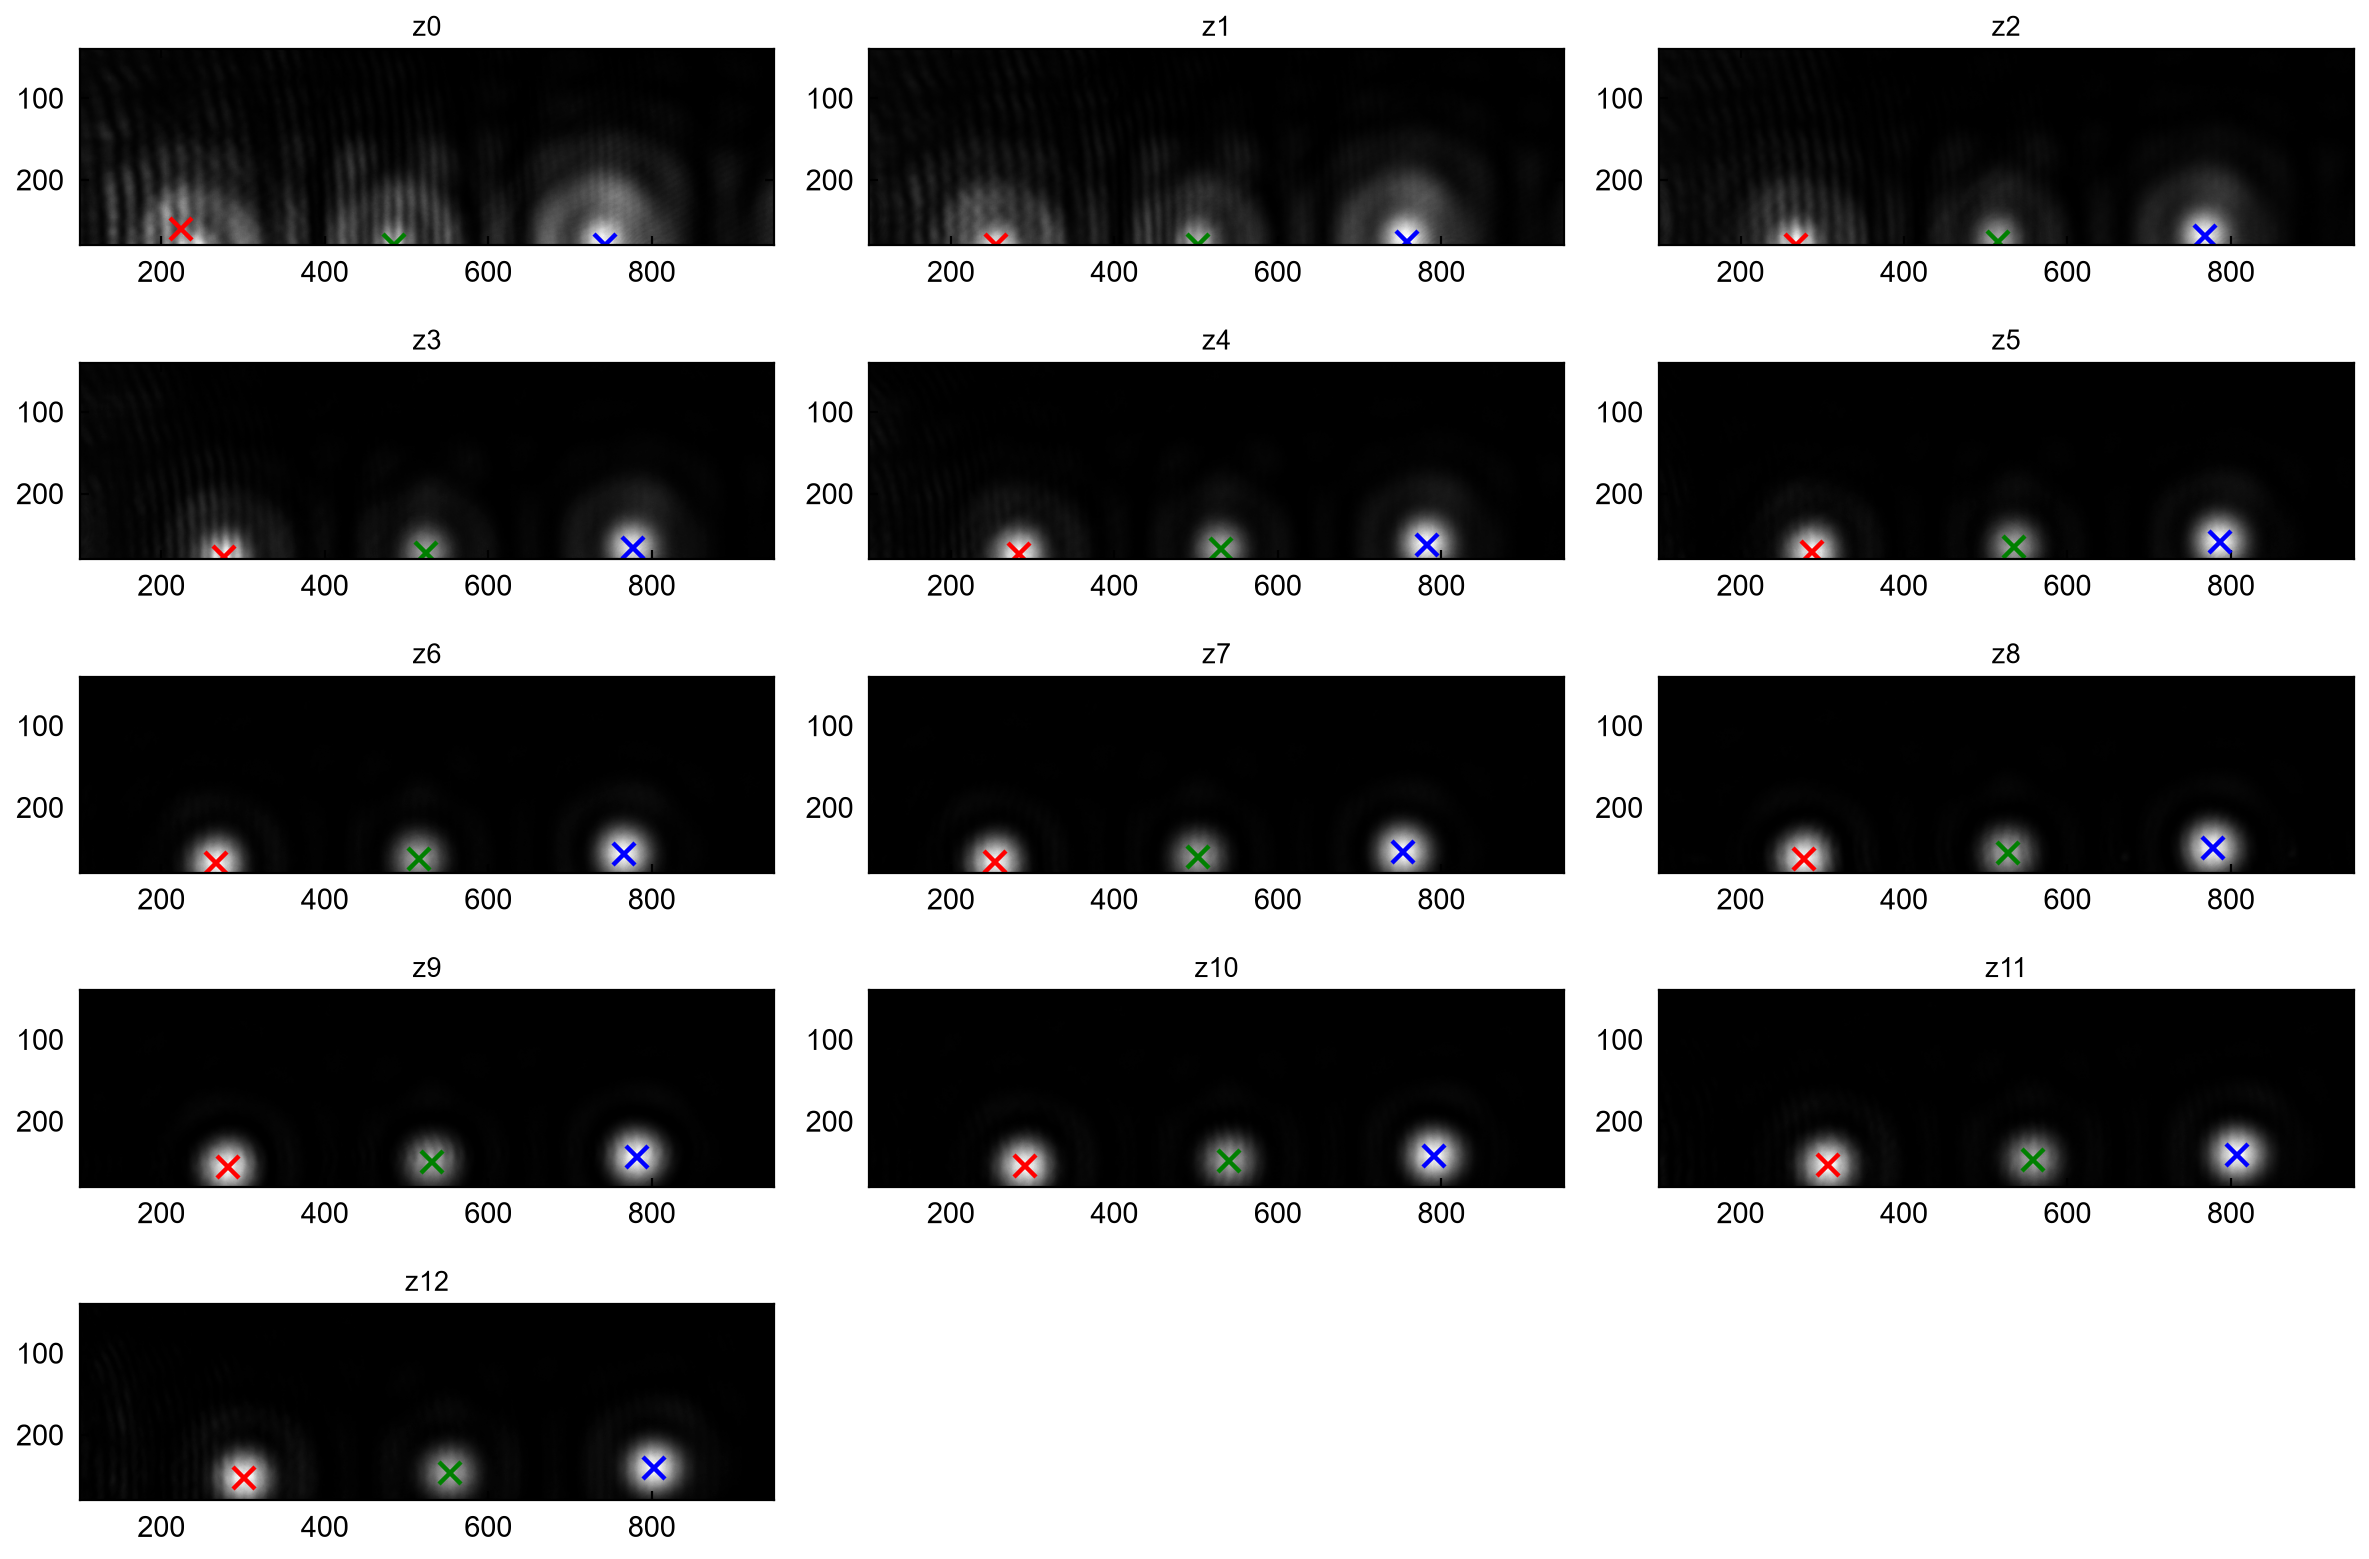

In [9]:
# ============================================================
# SHOW ALL 15 IMAGES WITH FITTED CENTRES
# ============================================================

fig, axes = plt.subplots(
    5,
    3,
    figsize=(15, 10)
)

axes = axes.ravel()


for i, ax in enumerate(axes):

    if i >= len(images):
        ax.axis("off")
        continue


    image = images[i]

    ax.imshow(
        image,
        cmap="gray",
        origin="upper"
    )


    # fitted centres
    ax.plot(
        results_left[i]["x"],
        results_left[i]["y"],
        "rx",
        markersize=10,
        markeredgewidth=2,
        label=LEFT_LABEL
    )

    ax.plot(
        results_16[i]["x"],
        results_16[i]["y"],
        "gx",
        markersize=10,
        markeredgewidth=2,
        label=MID_LABEL
    )

    ax.plot(
        results_right[i]["x"],
        results_right[i]["y"],
        "bx",
        markersize=10,
        markeredgewidth=2,
        label=RIGHT_LABEL
    )


    ax.set_title(
        f"z{z_indices[i]}"
    )

    ax.set_xlim(
        100,
        950
    )

    ax.set_ylim(
        280,
        40
    )


plt.tight_layout()
plt.show()

In [10]:
# ============================================================
# EXTRACT CENTROIDS
# ============================================================

x_left = np.array([
    r["x"]
    for r in results_left
])

y_left = np.array([
    r["y"]
    for r in results_left
])


x_16 = np.array([
    r["x"]
    for r in results_16
])

y_16 = np.array([
    r["y"]
    for r in results_16
])


x_right = np.array([
    r["x"]
    for r in results_right
])

y_right = np.array([
    r["y"]
    for r in results_right
])


# ============================================================
# TRUE 2D SEPARATIONS
# ============================================================

d_left_16 = np.sqrt(
    (x_left - x_16)**2
    +
    (y_left - y_16)**2
)


d_right_16 = np.sqrt(
    (x_right - x_16)**2
    +
    (y_right - y_16)**2
)


print()
print("z    left-16 [px]    right-16 [px]")
print("-----------------------------------")

for i in range(len(z_cm)):

    print(
        f"{z_indices[i]:2d}    "
        f"{d_left_16[i]:9.3f}       "
        f"{d_right_16[i]:9.3f}"
    )


z    left-16 [px]    right-16 [px]
-----------------------------------
 0      261.122         258.135
 1      247.202         255.586
 2      247.015         253.769
 3      246.821         252.783
 4      246.832         252.086
 5      246.915         251.607
 6      247.281         251.184
 7      247.870         251.108
 8      248.688         250.931
 9      249.176         250.677
10      249.991         250.549
11      250.834         250.348
12      251.785         250.096



LEFT - 16
slope     = -0.07817 +/- 0.30125 px/cm
intercept = 249.818 px
R^2       = 0.0061

RIGHT - 16
slope     = -0.52983 +/- 0.08799 px/cm
intercept = 255.399 px
R^2       = 0.7672


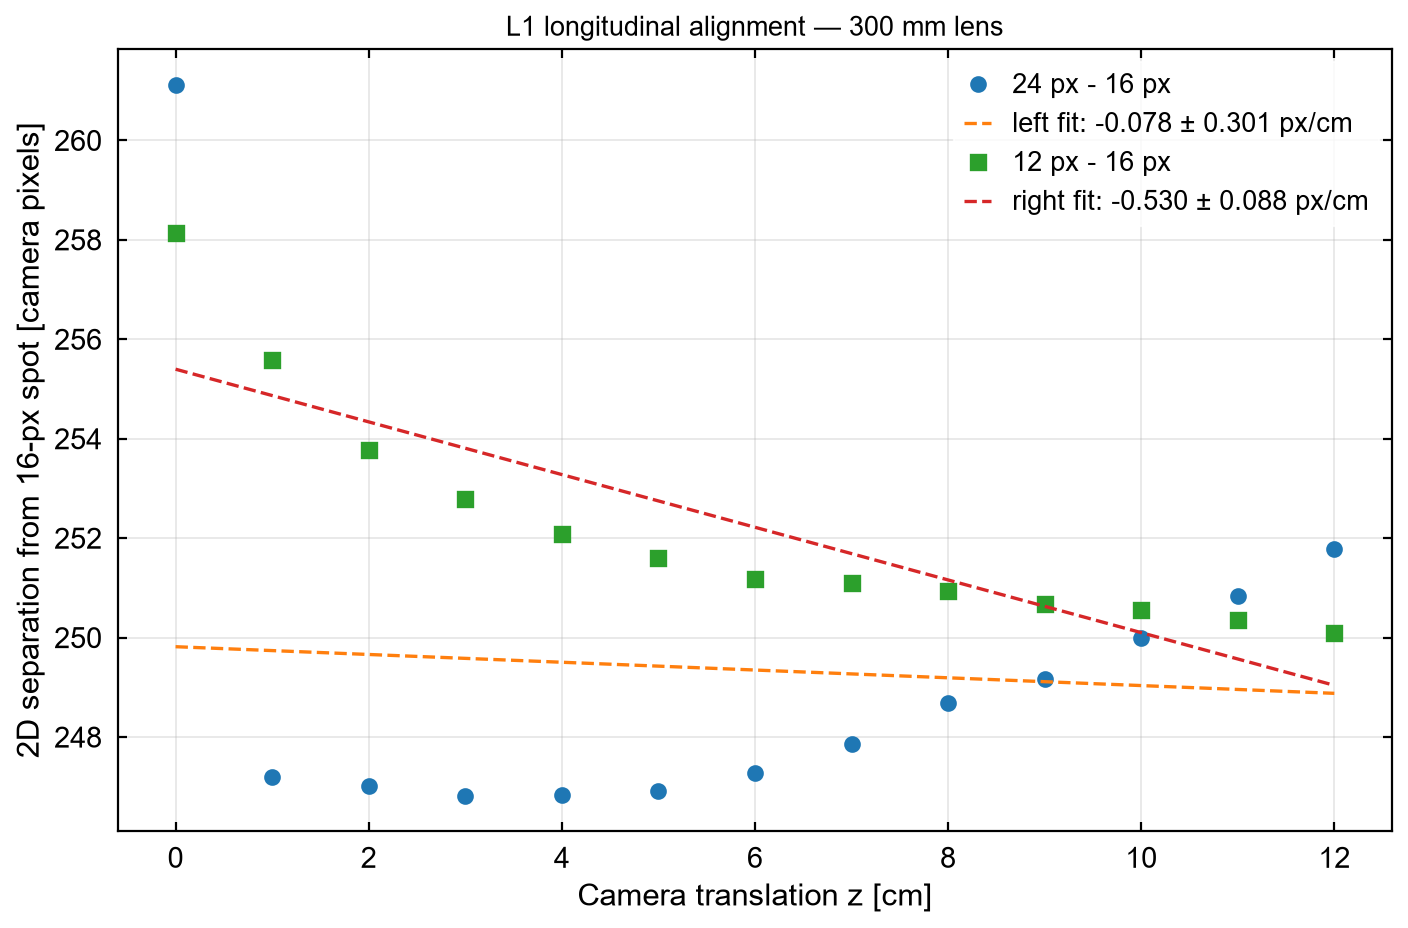

In [11]:
# ============================================================
# LINEAR FIT OF SPOT SEPARATIONS VS CAMERA Z
#
# d(z) = m z + b
#
# Perfect L1 longitudinal position:
#
#       m = 0
#
# ============================================================


# ------------------------------------------------------------
# Optional manual exclusions
#
# Example:
#
# EXCLUDE_LEFT = [13]
#
# if a particular left-hand fit is obviously contaminated.
# ------------------------------------------------------------

EXCLUDE_LEFT = []

EXCLUDE_RIGHT = []


mask_left = ~np.isin(
    z_indices,
    EXCLUDE_LEFT
)

mask_right = ~np.isin(
    z_indices,
    EXCLUDE_RIGHT
)


# ------------------------------------------------------------
# Linear regressions
# ------------------------------------------------------------

fit_left = linregress(
    z_cm[mask_left],
    d_left_16[mask_left]
)

fit_right = linregress(
    z_cm[mask_right],
    d_right_16[mask_right]
)


print()
print("==========================================")
print("LEFT - 16")
print("==========================================")

print(
    f"slope     = {fit_left.slope:.5f} "
    f"+/- {fit_left.stderr:.5f} px/cm"
)

print(
    f"intercept = {fit_left.intercept:.3f} px"
)

print(
    f"R^2       = {fit_left.rvalue**2:.4f}"
)


print()
print("==========================================")
print("RIGHT - 16")
print("==========================================")

print(
    f"slope     = {fit_right.slope:.5f} "
    f"+/- {fit_right.stderr:.5f} px/cm"
)

print(
    f"intercept = {fit_right.intercept:.3f} px"
)

print(
    f"R^2       = {fit_right.rvalue**2:.4f}"
)


# ============================================================
# PLOT
# ============================================================

z_dense = np.linspace(
    z_cm.min(),
    z_cm.max(),
    500
)


plt.figure(
    figsize=(9, 6)
)


# ------------------------------------------------------------
# Left
# ------------------------------------------------------------

plt.plot(
    z_cm,
    d_left_16,
    "o",
    label=f"{LEFT_LABEL} - 16 px"
)

plt.plot(
    z_dense,
    fit_left.intercept
    +
    fit_left.slope*z_dense,
    "--",
    label=(
        f"left fit: "
        f"{fit_left.slope:.3f} ± "
        f"{fit_left.stderr:.3f} px/cm"
    )
)


# ------------------------------------------------------------
# Right
# ------------------------------------------------------------

plt.plot(
    z_cm,
    d_right_16,
    "s",
    label=f"{RIGHT_LABEL} - 16 px"
)

plt.plot(
    z_dense,
    fit_right.intercept
    +
    fit_right.slope*z_dense,
    "--",
    label=(
        f"right fit: "
        f"{fit_right.slope:.3f} ± "
        f"{fit_right.stderr:.3f} px/cm"
    )
)


plt.xlabel(
    "Camera translation z [cm]"
)

plt.ylabel(
    "2D separation from 16-px spot [camera pixels]"
)

plt.title(
    "L1 longitudinal alignment — 300 mm lens"
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()